In [1]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import matplotlib as mpl
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq, minimize_scalar
import numpy.ma as ma
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator
from astropy.time import Time
from typing import Union, List
from scipy.signal import find_peaks

import frb_functions

from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from matplotlib.ticker import ScalarFormatter

In [4]:
def update_spines(fig, width=2.0, tick_labelsize=20, tick_width=2):
    """Sets the linewidth for all spines and adjusts tick parameters for all axes in a figure."""
    for ax in fig.get_axes():
        for spine in ax.spines.values():
            spine.set_linewidth(width)
    
        ax.tick_params(axis='both', which='major', direction='out', length=10, width=tick_width, labelsize=tick_labelsize)
        ax.tick_params(axis='both', which='minor', direction='out', length=5, width=tick_width, labelsize=tick_labelsize)

In [49]:
def masked_percentile(arr, q):
    return np.percentile(arr.compressed(), q)

In [5]:
def burst_database():

    b01_mid = {"file" : "/data1/omar/sfxc/frb240619d/p55025_28/p55025_28_64us_500KHz_StokesI_DM464857.cor_Wb.fil",
          "dm" : 464.857,
          "burst_tstamp" : 0.3398,
          "tdown" : 1,
          "fdown" : 1,
          "xwin" : 3.55,
          "ylim_b": -200,
          "ylim_t": 1300,
          "burst_id" : "B01-Wb"               
          }
    ################
    b02_mid = {"file" : "/data1/omar/sfxc/frb240619d/p55038_23/p55038_23_64us_500KHz_StokesI_DM464857.cor_Wb.fil",
          "dm" : 464.857,
          "burst_tstamp" : 0.723,
          "tdown" : 1,
          "fdown" : 1,
          "xwin" : 11,
          "ylim_b": -4,
          "ylim_t": 15,
          "burst_id" : "B02-Wb"               
          }
    ################
    b05_mid = {"file" : "/data1/omar/sfxc/frb240619d/p55048_24/p55048_24_64us_500KHz_StokesI_DM465106.cor_Wb.fil",
          "dm" : 465.106,
          "burst_tstamp" : 1.013,
          "tdown" : 1,
          "fdown" : 1,
          "xwin" : 25,
          "ylim_b": -4,
          "ylim_t": 11,
          "burst_id" : "B05-Wb"
          }
    ################
    b06_mid = {"file" : "/data1/omar/sfxc/frb240619d/p55049_25/p55049_25_64us_500KHz_StokesI_DM465095.cor_Wb.fil",
          "dm" : 465.095,
          "burst_tstamp" : 0.306,
          "tdown" : 1,
          "fdown" : 1,
          "xwin" : 11,
          "ylim_b": -15,
          "ylim_t": 100,
          "burst_id" : "B06-Wb"
          }
    ################
    b07_mid = {"file" : "/data1/omar/sfxc/frb240619d/p55065_29/p55065_29_64us_500KHz_StokesI_DM465294.cor_Wb.fil",
          "dm" : 465.294,
          "burst_tstamp" : 0.756,
          "tdown" : 1,
          "fdown" : 1,
          "xwin" : 10,
          "ylim_b": -5,
          "ylim_t": 15,
          "burst_id" : "B07-Wb"
          }
    ################
    b10_mid = {"file" : "/data1/omar/sfxc/frb240619d/p55074_30/p55074_30_64us_500KHz_StokesI_DM464857.cor_Wb.fil",
          "dm" : 464.857,
          "burst_tstamp" : 1.233,
          "tdown" : 1,
          "fdown" : 1,
          "xwin" : 25,
          "ylim_b": -5,
          "ylim_t": 15,
          "burst_id" : "B10-Wb"
          }
    ################
    b11_mid = {"file" : "/data1/omar/sfxc/frb240619d/p55081_19/p55081_19_64us_500KHz_StokesI_DM465266.cor_Wb.fil",
          "dm" : 465.266,
          "burst_tstamp" : 0.6789,
          "tdown" : 1,
          "fdown" : 1,
          "xwin" : 3,
          "ylim_b": -8,
          "ylim_t": 45,
          "burst_id" : "B11-Wb"
          }
    ################

    burst_dict = [b01_mid, b02_mid, b05_mid, b06_mid,\
                  b07_mid, b10_mid, b11_mid,]

    return burst_dict

In [62]:
def load_fil(burst,burst_tstamp, downsamp_t=1,downsamp_f=1):

    burst = your.Your(burst)

    header_dict = frb_functions.your_header_to_dict(burst)
    tsamp = header_dict["tsamp"]
    nbins = header_dict["nspectra"]
    fsamp = header_dict["foff"] * -1
    freqs = header_dict["freqs"] # in Mhz
    
    tmin = 0.0
    tmax = nbins * burst.tsamp # seconds
    fmin = header_dict["fmin"]
    fmax = header_dict["fmax"]
    extent_b = [tmin, tmax, fmin, fmax]

    offset = burst_tstamp #
    extent_b[0] = (tmin - offset) * 1000
    extent_b[1] = (tmax - offset) * 1000
    print(f"the extent of the data is: {extent_b}")
    
    #time increasing, freq decreasing
    print("loading in the data")
    d = frb_functions.get_data(burst, nstart=0, nsamp=nbins, npoln=1)

    sides_bandpass = 'right' 
    scale_bandpass = 3

    #Correcting the bandpass
    stokes_i = frb_functions.correct_bandpass(d, sides=sides_bandpass, scale=scale_bandpass)

    bandwidth = header_dict["bw"] * - 1
    nchans =header_dict["nchans"]
    band_edges = frb_functions.get_subband_edges(bandwidth, nchans)
    
    stokes_i = frb_functions.mask_array(array=stokes_i, bad_chan_idx=band_edges)

    #Correcting the bandpass
    stokes_i = frb_functions.correct_bandpass(stokes_i, sides=sides_bandpass, scale=scale_bandpass)
    
    print(f"downsample factors are: time:{downsamp_t} and freq:{downsamp_f}")
    if downsamp_f > 1 or downsamp_t > 1:
        print(f"running downsampling and correcting bandpass")
        stokes_i = frb_functions.downsample(stokes_i, freqf=downsamp_f, timef=downsamp_t)
        tsamp = tsamp * downsamp_t
        fsamp = fsamp * downsamp_f
        stokes_i = frb_functions.correct_bandpass(stokes_i, sides=sides_bandpass, scale=scale_bandpass)
        downsamp_flag = True
    else:
        downsamp_flag = False

    #Create x grid to plot the step function. 
    x_grid = np.linspace(extent_b[0], extent_b[1], endpoint=False, num=stokes_i.shape[1])

    prof = np.ma.mean(stokes_i,axis=0)
    stokes_i_normprof = frb_functions.normalize_1d(prof, sides=sides_bandpass, scale=scale_bandpass)
    print(f"peak_sn is {np.max(stokes_i_normprof):.2f}")
    
    new_quantiles = masked_percentile(stokes_i, (0.01, 99.99))

    print("#########")
    
    return stokes_i, stokes_i_normprof, x_grid, new_quantiles, extent_b, tsamp, fsamp

In [63]:
def dynamic_spectra_grid(fig_size=(18, 10)):
    """
    Generates a 2-row plot:
    - Top row has 4 panels (time series + dynamic spectra)
    - Bottom row has 3 panels
    """

    burst_dict = burst_database()

    # Define total layout: 2 rows (outer), 4 columns on top row, 3 on bottom
    fig = plt.figure(figsize=fig_size)

    outer_spec = gridspec.GridSpec(2, 4, figure=fig, width_ratios=[1]*4, height_ratios=[1]*2, hspace=0.2, wspace=0.23)

    for i, burst_db_val in enumerate(burst_dict):
        if i >= 7:  # Only show 7 bursts
            break

        row = 0 if i < 4 else 1
        col = i if i < 4 else i - 4

        # Nested grid: top = time series, bottom = dynamic spectrum
        inner_spec = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer_spec[row, col], height_ratios=[1, 2], hspace=0)

        # Load burst data
        stokes_i, stokes_i_normprof, x_grid, new_quantiles, extent, tsamp, fsamp = load_fil(
            burst_db_val["file"],
            burst_tstamp=burst_db_val["burst_tstamp"],
            downsamp_t=burst_db_val["tdown"],
            downsamp_f=burst_db_val["fdown"]
        )

        DM_value = burst_db_val["dm"]
        window_ms = burst_db_val["xwin"]
        maxSN = burst_db_val["ylim_t"]
        minSN = burst_db_val["ylim_b"]
        burst_id = burst_db_val["burst_id"]

        ax_ts = fig.add_subplot(inner_spec[0])
        ax_dyn = fig.add_subplot(inner_spec[1], sharex=ax_ts)

        # Plot time series
        ax_ts.plot(x_grid, stokes_i_normprof, color='black', drawstyle='steps-post')
        ax_ts.set_ylim(minSN, 1.3 * maxSN)
        ax_ts.yaxis.set_major_locator(ticker.FixedLocator([0, maxSN]))
        ax_ts.yaxis.set_minor_locator(ticker.FixedLocator([maxSN / 2]))
        ax_ts.tick_params(labelbottom=False, labelsize=18)

        # Plot dynamic spectrum
        ax_dyn.imshow(stokes_i, aspect='auto', interpolation='none',
                      extent=extent, vmin=new_quantiles[0], vmax=new_quantiles[1])
        ax_dyn.set_xlim(-window_ms, window_ms)
        ax_dyn.yaxis.set_major_locator(ticker.LinearLocator(4))
        ax_dyn.tick_params(labelsize=18)

        # Annotate
        ax_ts.text(0.04, 0.93, f"{burst_id}", transform=ax_ts.transAxes, fontsize=8, va='top', ha='left')
        
        ax_ts.text(0.98, 0.93, fr"DM = {DM_value:.3f}" + r" pc cm$^{-3}$", 
                   fontsize=8, va='top', ha='right', transform=ax_ts.transAxes)
        
        # Y-axis labels for leftmost panels
        if col == 0:
            ax_ts.set_ylabel("S/N", fontsize=18)
            ax_dyn.set_ylabel("Frequency (GHz)", fontsize=18, labelpad=15)
            ax_dyn.set_yticks([1300, 1250, 1207])
            ax_dyn.set_yticklabels([1.3, 1.25, 1.2])

        else:
            #ax_ts.tick_params(labelleft=False)
            ax_dyn.tick_params(labelleft=False)

        # X-axis labels for bottom row
        if row == 1:
            ax_dyn.set_xlabel("Time (ms)", fontsize=18)

    update_spines(fig, tick_labelsize=18)

    plot_name = "wb_family_plot_V1"
    fig.savefig(plot_name + ".pdf", dpi=300, bbox_inches='tight')
    
    fig.savefig(plot_name + ".png", facecolor='white', \
            transparent=False, format = 'png',bbox_inches='tight', dpi=300)

    plt.show()

the extent of the data is: [-339.8, 1452.2, 1207.0, 1335.0]
loading in the data
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32
downsample factors are: time:1 and freq:1
peak_sn is 1333.55
#########
the extent of the data is: [-723.0, 1069.0, 1207.0, 1335.0]
loading in the data
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32
downsample factors are: time:1 and freq:1
peak_sn is 14.31
#########
the extent of the data is: [-1012.9999999999999, 1803.0, 1207.0, 1335.0]
loading in the data
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32
downsample factors are: time:1 and freq:1
peak_sn is 9.83
#########
the extent of the data is: [-306.0, 1485.9999999999998, 1207.0, 1335.0]
loading in the data
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32
downsample factors are: time:1 and freq:1
peak_sn is 98.32


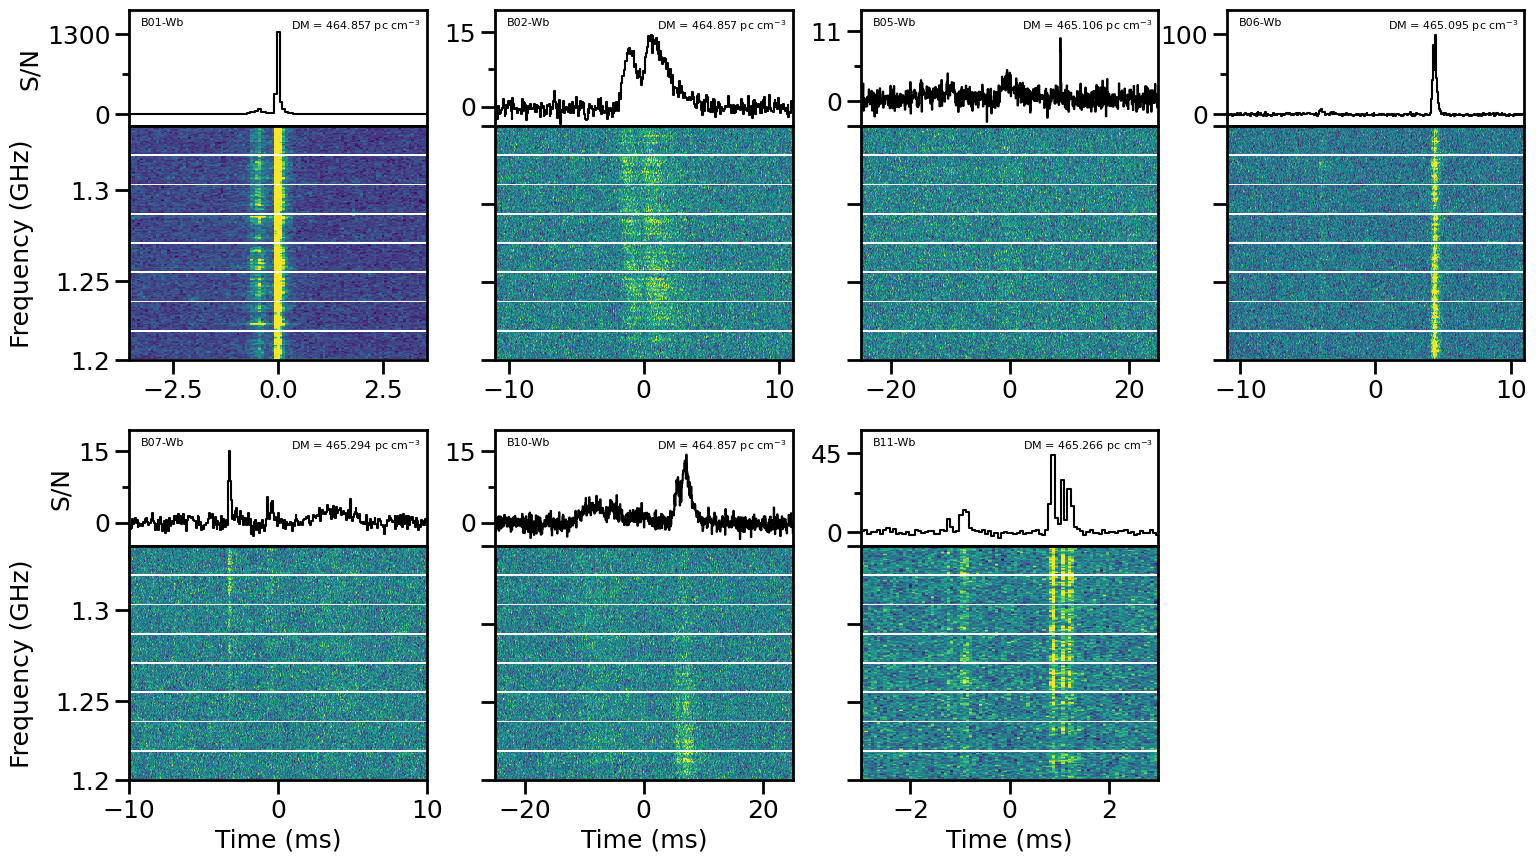

In [64]:
dynamic_spectra_grid()